# This file is to test the processed data before it is used for training

## Tests included:
- Correct flare time intervals retrieved (integer)
- Correct number of flares retrieved (integer)
- Correct separation of light curves into flare/non-flare data
- Correct flags added to flare/non-flare data (binary)

In [10]:
#imports modules
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#set root and import functions
import sys
sys.path.insert(0, str(Path.cwd().parent))
from src.utilities import build_individual_grb_table, separate_flare_data

In [11]:
#read in data
df=pd.read_csv('../data/xrt_data_from_phd.csv')

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.item(), a.any() or a.all().

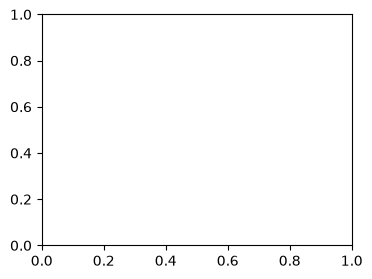

In [ ]:
#load and test a light curve for a single random GRB
choice=np.random.choice(df['GRB'].unique())
data=build_individual_grb_table(df,choice)
# print(data.columns)

#separate the flare data and append the binary flare flags
flare_data,non_flare_data,full_data=separate_flare_data(data)

#make plot 
fig,axs=plt.subplots(figsize=(4,3))

#plot flare data
if flare_data is not None:
    axs.errorbar(flare_data['Time'], flare_data['Rate'], xerr=[np.abs(flare_data['TimeNeg']),np.abs(flare_data['TimePos'])], yerr=[np.abs(flare_data['RateNeg']),np.abs(flare_data['RatePos'])] ,fmt='o', markersize=3,capsize=2, color='red', label='Flare Data')

#plot non flare data
if non_flare_data is not None:
    axs.errorbar(non_flare_data['Time'], non_flare_data['Rate'], xerr=[np.abs(non_flare_data['TimeNeg']),np.abs(non_flare_data['TimePos'])], yerr=[np.abs(non_flare_data['RateNeg']),np.abs(non_flare_data['RatePos'])] ,fmt='o', markersize=3,capsize=2, color='blue', label='Non-Flare Data')

# #plot full LC
# axs.errorbar(full_data['Time'], full_data['Rate'], xerr=[np.abs(full_data['TimeNeg']),np.abs(full_data['TimePos'])], yerr=[np.abs(full_data['RateNeg']),np.abs(full_data['RatePos'])] ,fmt='o', markersize=3,capsize=2,color='blue' if full_data['Flare_flag']==0 else 'red', label='Non-flare Data')

#format and produce plot
axs.set_xscale('log')
axs.set_yscale('log')
axs.set_xlabel('Time (s)')
axs.set_ylabel('Count rate (arbitrary units)')
axs.set_title('GRB {} X-ray Light Curve'.format(data['GRB'].iloc[0]))
axs.legend()
plt.show()


In [13]:
# Compare the different versions (works whether a dataframe is None or empty)
print('Flare data:')
print(flare_data.head(4) if flare_data is not None else 'None (no flares)')

print('\nNon-flare data:')
print(non_flare_data.head(4) if non_flare_data is not None else 'None (no non-flare data)')

print('\nFull data:')
print(full_data.head(4))

# Sanity check: flare + non-flare rows should equal the full data
n_flare=0 if flare_data is None else len(flare_data)
print(f'\nflare ({n_flare}) + non-flare ({len(non_flare_data)}) = {n_flare + len(non_flare_data)}, full={len(full_data)}')
print('\nNumber of data points with flare flags: {} positive and {} negative'.format(len(full_data[full_data['Flare_flag']==1]),len(full_data[full_data['Flare_flag']==0])))

Flare data:
           GRB     Time TimePos TimeNeg      Rate   RatePos   RateNeg  \
198797  050716  163.967   0.564  -0.685  42.55362  6.390504 -6.434659   
198798  050716  165.274    0.95  -0.744  30.88848  4.740139 -4.774819   
198799  050716  166.985   0.687  -0.761  36.12566  5.540644  -5.57805   
198800  050716  168.232   0.764  -0.559   39.9415  6.006954 -6.057081   

         lctype Flare_1_start Flare_1_end  ... Flare_10_start Flare_10_end  \
198797  Oddball       163.282     193.577  ...            NaN          NaN   
198798  Oddball       163.282     193.577  ...            NaN          NaN   
198799  Oddball       163.282     193.577  ...            NaN          NaN   
198800  Oddball       163.282     193.577  ...            NaN          NaN   

       Flare_11_start Flare_11_end Flare_12_start Flare_12_end Flare_13_start  \
198797            NaN          NaN            NaN          NaN            NaN   
198798            NaN          NaN            NaN          NaN       